## MTL Trajet: 24 Outward Return Movement Pairs (Flag 24)

### Dataset Overview

Paired outward and return Montréal movements with shared pair IDs, reversed endpoints, activity stays, modes, route directness, point speeds, and return intervals.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze patterns in paired outward and return movements.

Role: Urban mobility-pattern analyst


Category: Paired outward and return Montréal movements with shared pair IDs, reversed endpoints, activity stays, modes, route directness, point speeds, and return intervals.

Distances and directness are calculated from delivered GPS polylines; point speeds, trip durations, chain timing, and paired-leg timing are synchronized with the supplied point table. Route directness ratio is route distance divided by straight-line distance, so it is at least 1 and lower values indicate more direct routes.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Do outward and return legs preserve mode while differing in route directness and speed profile?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

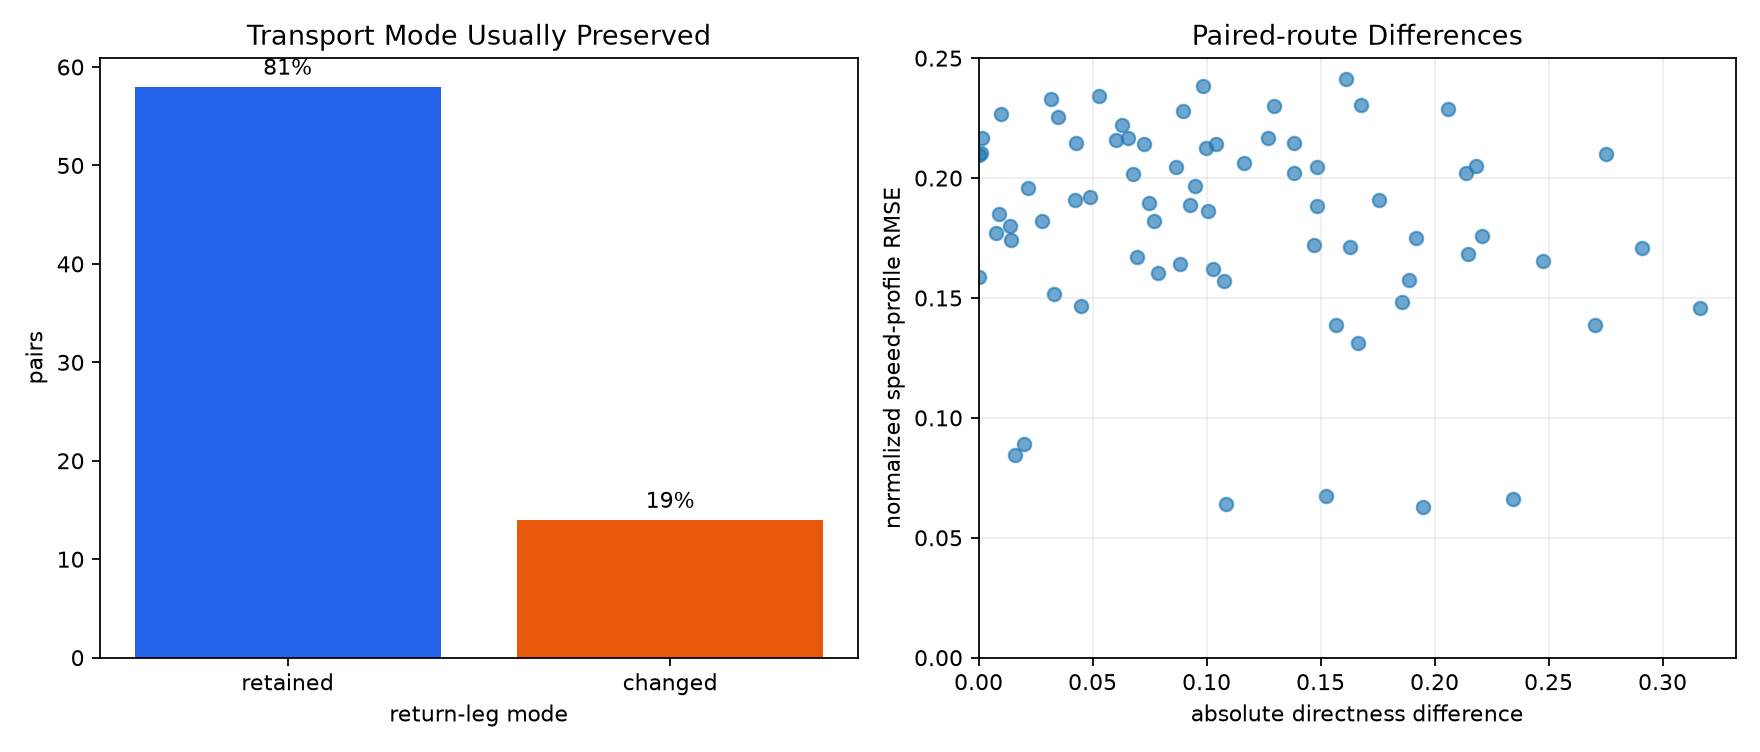

In [ ]:
df.groupby("pair_id").first()[
    ["mode_changed_within_pair", "directness_difference", "speed_profile_difference"]
].describe()
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/paired_mode_route_speed_differences.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "paired_mode_route_speed",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Mode, Route, and Speed within Pairs",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/paired_mode_route_speed_differences.png"
  },
  "question": "Do outward and return legs preserve mode while differing in route directness and speed profile?",
  "code": "df.groupby('pair_id').first()[['mode_changed_within_pair','directness_difference','speed_profile_difference']].describe()",
  "insight": "Outbound and return legs usually preserve transport mode, but often differ in route directness and speed profiles.",
  "insight_type": "overall_pattern",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "user_id",
    "trip_purpose",
    "transport_mode",
    "gps_position",
    "point_speed"
  ]
}

### **Question 2**: How do work, shopping, dining, and leisure pairs differ in destination-stay duration?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

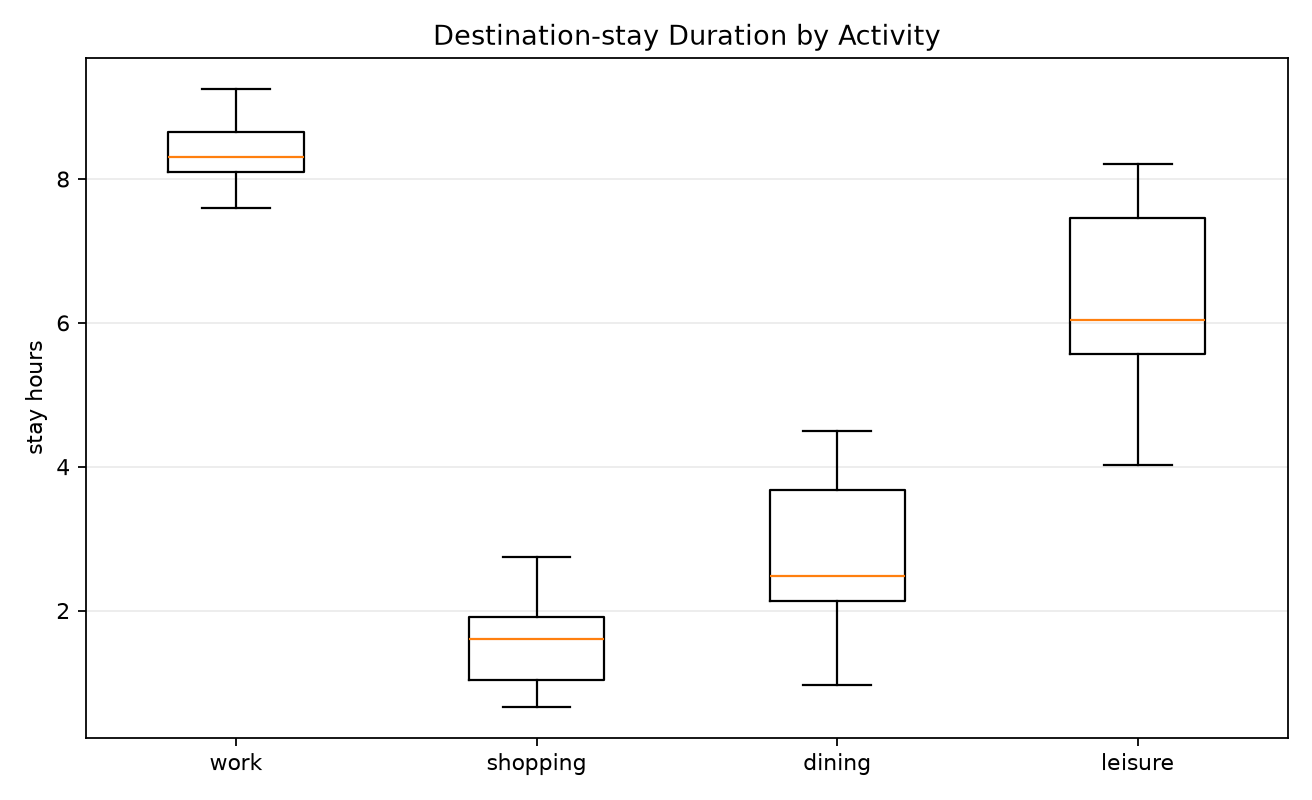

In [ ]:
df.groupby("pair_id").first().groupby("activity_purpose").destination_stay_hours.agg(
    ["median", "mean", "std"]
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/stay_duration_by_activity.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "activity_stay_duration",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Destination-stay Duration by Activity",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/stay_duration_by_activity.png"
  },
  "question": "How do work, shopping, dining, and leisure pairs differ in destination-stay duration?",
  "code": "df.groupby('pair_id').first().groupby('activity_purpose').destination_stay_hours.agg(['median','mean','std'])",
  "insight": "Work-based pairs have longer and more regular destination stays, while shopping and dining pairs show shorter and more variable activity intervals.",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id",
    "user_id"
  ]
}

### **Question 3**: Are longer destination stays more likely to be followed by a mode change?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

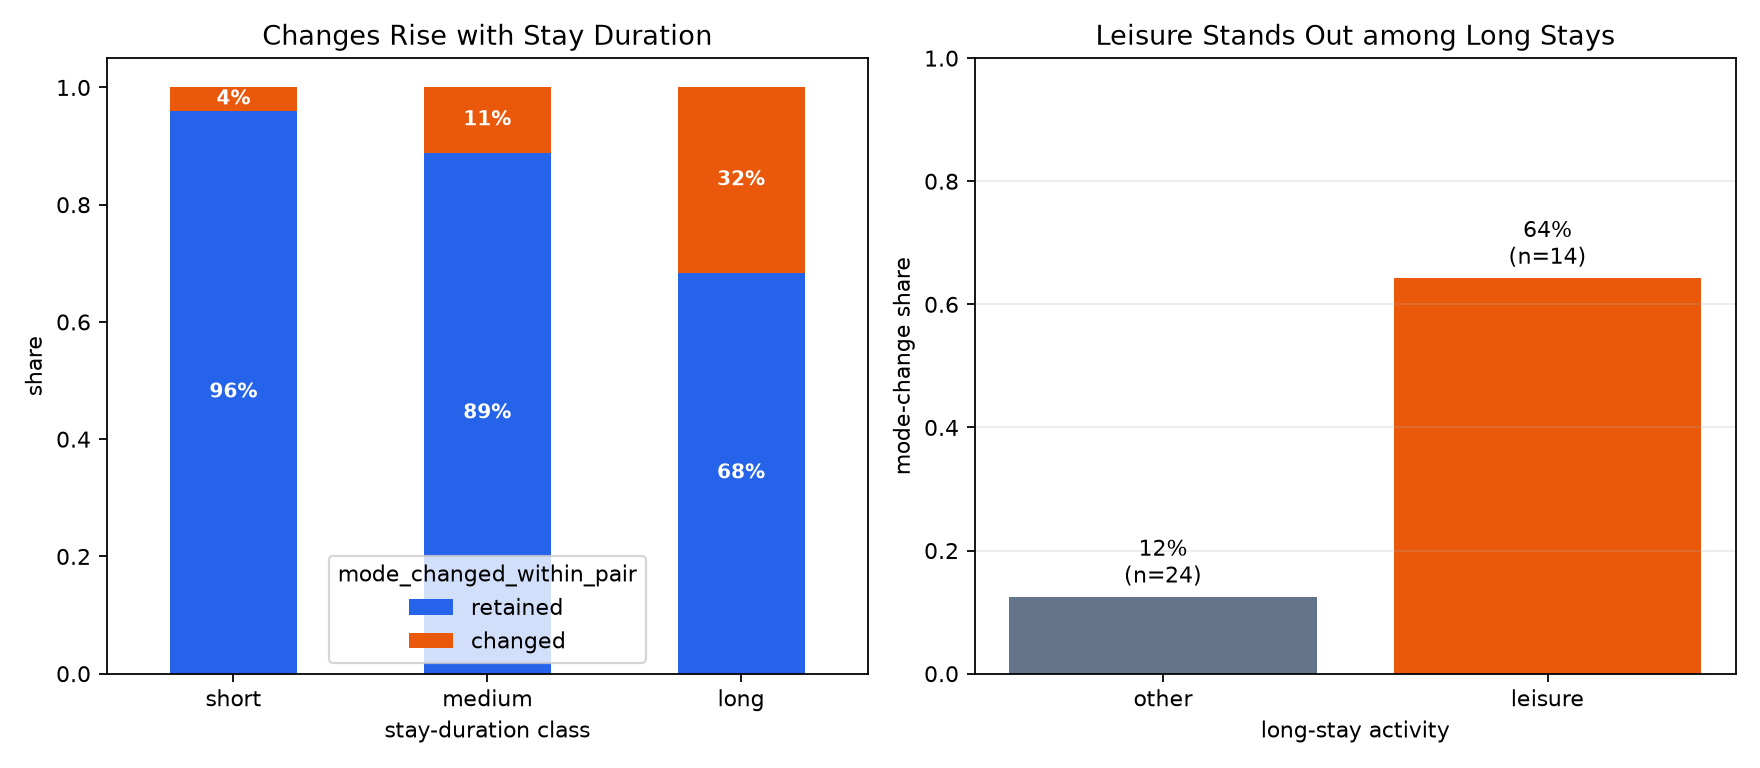

In [ ]:
pairs = df.groupby("pair_id").first()
pairs.groupby(
    pd.cut(pairs.destination_stay_hours, [0, 3, 5, 12]), observed=False
).mode_changed_within_pair.mean()
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/stay_duration_mode_change.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "stay_duration_mode_change",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Stay Duration and Return-mode Change",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/stay_duration_mode_change.png"
  },
  "question": "Are longer destination stays more likely to be followed by a mode change?",
  "code": "pairs=df.groupby('pair_id').first(); pairs.groupby(pd.cut(pairs.destination_stay_hours,[0,3,5,12]),observed=False).mode_changed_within_pair.mean()",
  "insight": "Pairs with longer destination stays are more likely to change transport mode on the return leg, especially for leisure-related trips.",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "user_id",
    "trip_purpose",
    "transport_mode"
  ]
}

### **Question 4**: How does outward departure period relate to the interval before return?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

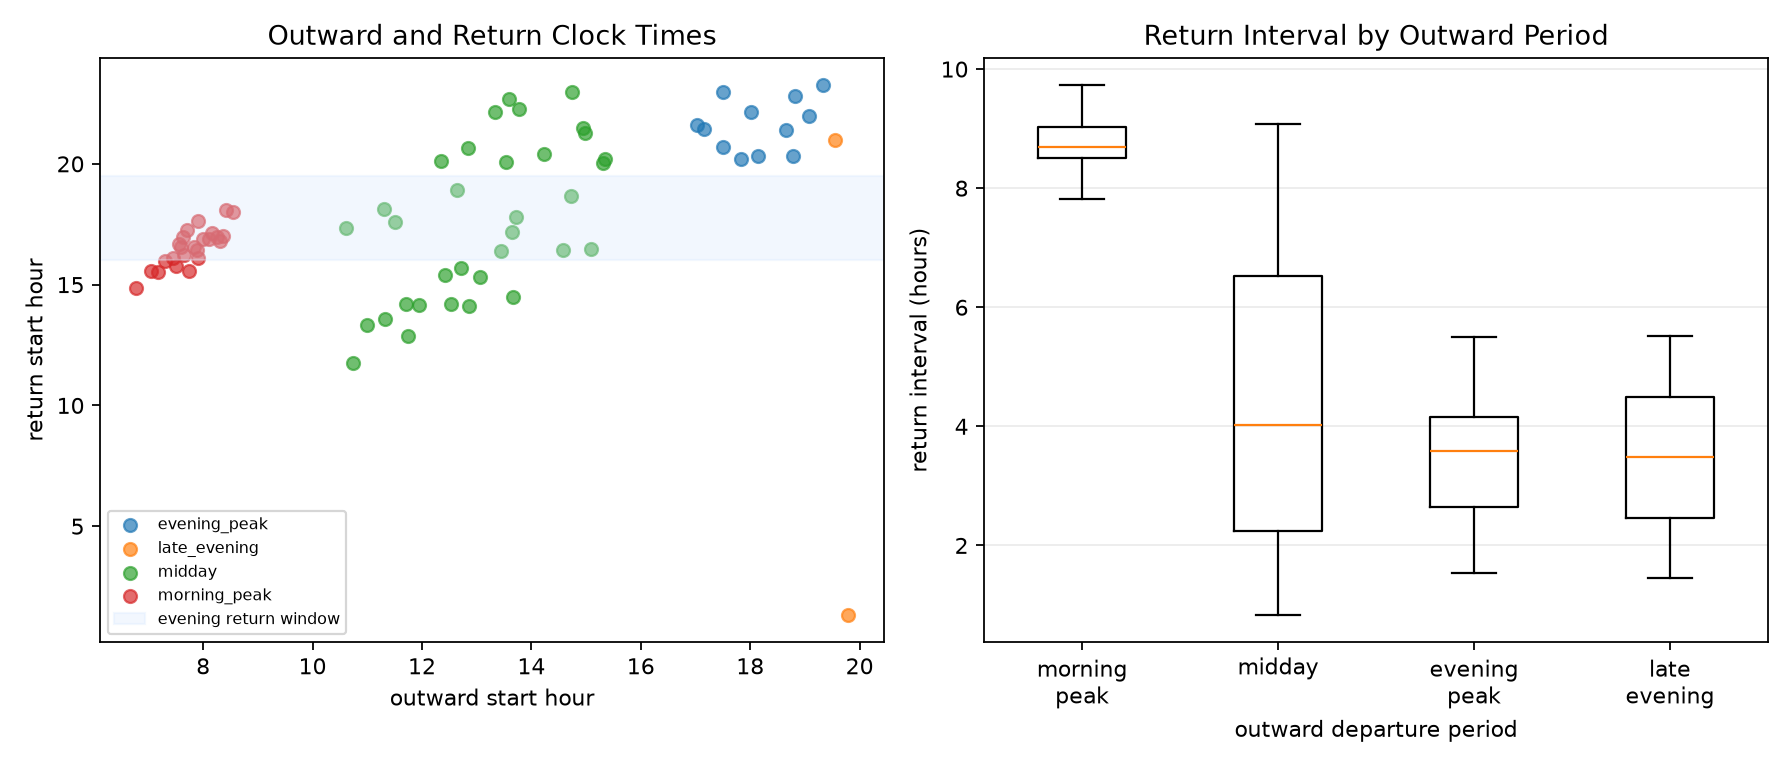

In [ ]:
df[df.pair_leg.eq("outward")].groupby("departure_period").return_interval_hours.agg(
    ["median", "mean", "std"]
)
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/outward_time_return_interval.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "outward_return_timing",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Outward Time and Return Interval",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/outward_time_return_interval.png"
  },
  "question": "How does outward departure period relate to the interval before return?",
  "code": "df[df.pair_leg.eq('outward')].groupby('departure_period').return_interval_hours.agg(['median','mean','std'])",
  "insight": "Morning outward trips are commonly paired with evening returns, while midday outward trips tend to have much shorter return intervals.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "trajectory_id",
    "user_id",
    "trip_purpose"
  ]
}

### Summary of Findings (Flag 24)

Outward and return legs usually preserve mode but differ in geometry and speed shape. Work stays are long and regular; shopping and dining stays are shorter and variable. Longer stays, particularly leisure stays, have more return-mode changes, while morning departures have the longest return intervals.